# Búsqueda de la señal de 852 nm (Rama A)

Montaje de la etapa 2: el 822 nm (bombeo) y el 794 nm (semilla) atraviesan copropagantes la celda de Cs a 80 °C. Se barre $\lambda_{822}$ a través de la resonancia de dos fotones $6S_{1/2}\to 8S_{1/2}$ con el 794 fijo.

* **Canal A** (PMT lateral): fluorescencia azul de la cascada $8S\to 7P\to 6S$. Marca $\Delta_2 = 0$ en cada barrido.
* **Canal B** (fibra → monocromador en 852.3–852.4 nm → SPCM): la luz que sale de la celda hacia adelante, atenuada por filtros ND colocados antes del acoplador a la fibra.

**Pregunta:** ¿muestra el canal B alguna estructura ligada al pico de dos fotones del canal A? En celda gruesa, $I_{852}\propto|\chi^{(3)}_P/\chi_{ef}|^2$ conserva solo la resonancia de dos fotones, así que una señal de FWM debería seguir la forma del pico del canal A.

Columnas de los archivos (iguales a `Rama_A/Fluorescencia/newdata/`): col 1 $\lambda_{822}$ (nm), col 2 Singles A (cuentas/s), col 3 Singles B (cuentas/s), col 4 $\nu_{822}$ (THz). El nombre sigue `λ794-P794-P822-T-corrientePMT-aperturaSlave-λ852-FiltrosND`.

In [ ]:
import sys
sys.path.append('../..')  # carpeta raíz del repositorio, donde está constants.py
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import medfilt
from scipy.stats import pearsonr

from constants import c, kB, cte

C_LIGHT = c*1e-3  # nm*THz  <

# Carpeta Rama_A/Deteccion_852 (en Colab: clonar el repo y hacer %cd Proyecto/Rama_A/Deteccion_852)
BASE = '.'
T_EXP = 0.1  # tiempo de exposición del QuTau [s] (supuesto: el mismo de Rama_A/Fluorescencia/newdata)

## Lectura y limpieza

Se descartan las primeras filas con cuentas nulas (arranque de la adquisición) y los saltos espurios del medidor de longitud de onda, que aparecen como puntos aislados lejos de la rampa (|λ − mediana móvil| > 3×10⁻⁴ nm).

In [3]:
def parse(name):
    # Parámetros del montaje a partir del nombre del archivo
    p = name.split('-')
    return dict(lam794=float(p[0]), P794=float(p[1][:-2]), P822=float(p[2][:-2]),
                T=float(p[3][:-1]), lam852=float(p[6]), ND=int(p[7][:-2]))

def load(path):
    d = np.loadtxt(path)
    lam, A, B = d[:, 1], d[:, 2], d[:, 3]
    ok = (A > 0) & (B > 0) & (np.abs(lam - medfilt(lam, 5)) < 3e-4)
    t = np.linspace(0, 1, len(lam))[ok]  # orden de adquisición, para la deriva lenta
    return dict(lam=lam[ok], A=A[ok], B=B[ok], t=t, n_bad=int((~ok).sum()))

def gauss(x, c0, x0, s, a):
    return c0 + a*np.exp(-(x - x0)**2/(2*s**2))

def binned(x, y, bin_w):
    # Media y desviación estándar de y en bins de ancho bin_w en x
    xb = np.floor(x/bin_w)*bin_w + bin_w/2
    ux = np.unique(xb)
    return ux, np.array([y[xb == u].mean() for u in ux]), np.array([y[xb == u].std() for u in ux])

## Prueba: ¿hay en el canal B una componente con la forma del pico del canal A?

1. Se ajusta una gaussiana al canal A en función de la desintonía del 822, $x = \nu_{822} - \bar\nu_{822}$ (MHz). Así se obtienen el centro $x_0$ y el ancho $\sigma$ de la resonancia de dos fotones en ese barrido.
2. Con esa forma fija, $g(x) = e^{-(x-x_0)^2/2\sigma^2}$, se ajusta el canal B con
$$B = b_0 + b_t\,(t - \tfrac12) + b_1\,g(x),$$
donde $b_0$ es el fondo, $b_t$ una deriva lenta en el tiempo de adquisición y $b_1$ la amplitud de una posible señal ligada a $\Delta_2 = 0$.
3. Si no hay señal, $b_1$ debe ser compatible con cero. Se reporta $z = b_1/\sigma_{b_1}$ y el límite superior a $2\sigma$ de la señal relativa al fondo, $(\max(b_1,0) + 2\sigma_{b_1})/b_0$. Como los filtros ND atenúan por igual la señal y el fondo, este cociente no depende del filtro.

También se compara la dispersión de B con el ruido de Poisson esperado, $\sqrt{b_0/T_{exp}}$.

Como referencia, el ancho Doppler esperado del pico de dos fotones con haces copropagantes, en la frecuencia del 822, es $\mathrm{FWHM} = 2\sqrt{\ln 2}\,u/\lambda_{822}$, con $u=\sqrt{2k_BT/m_{Cs}}$ a la temperatura de la celda.

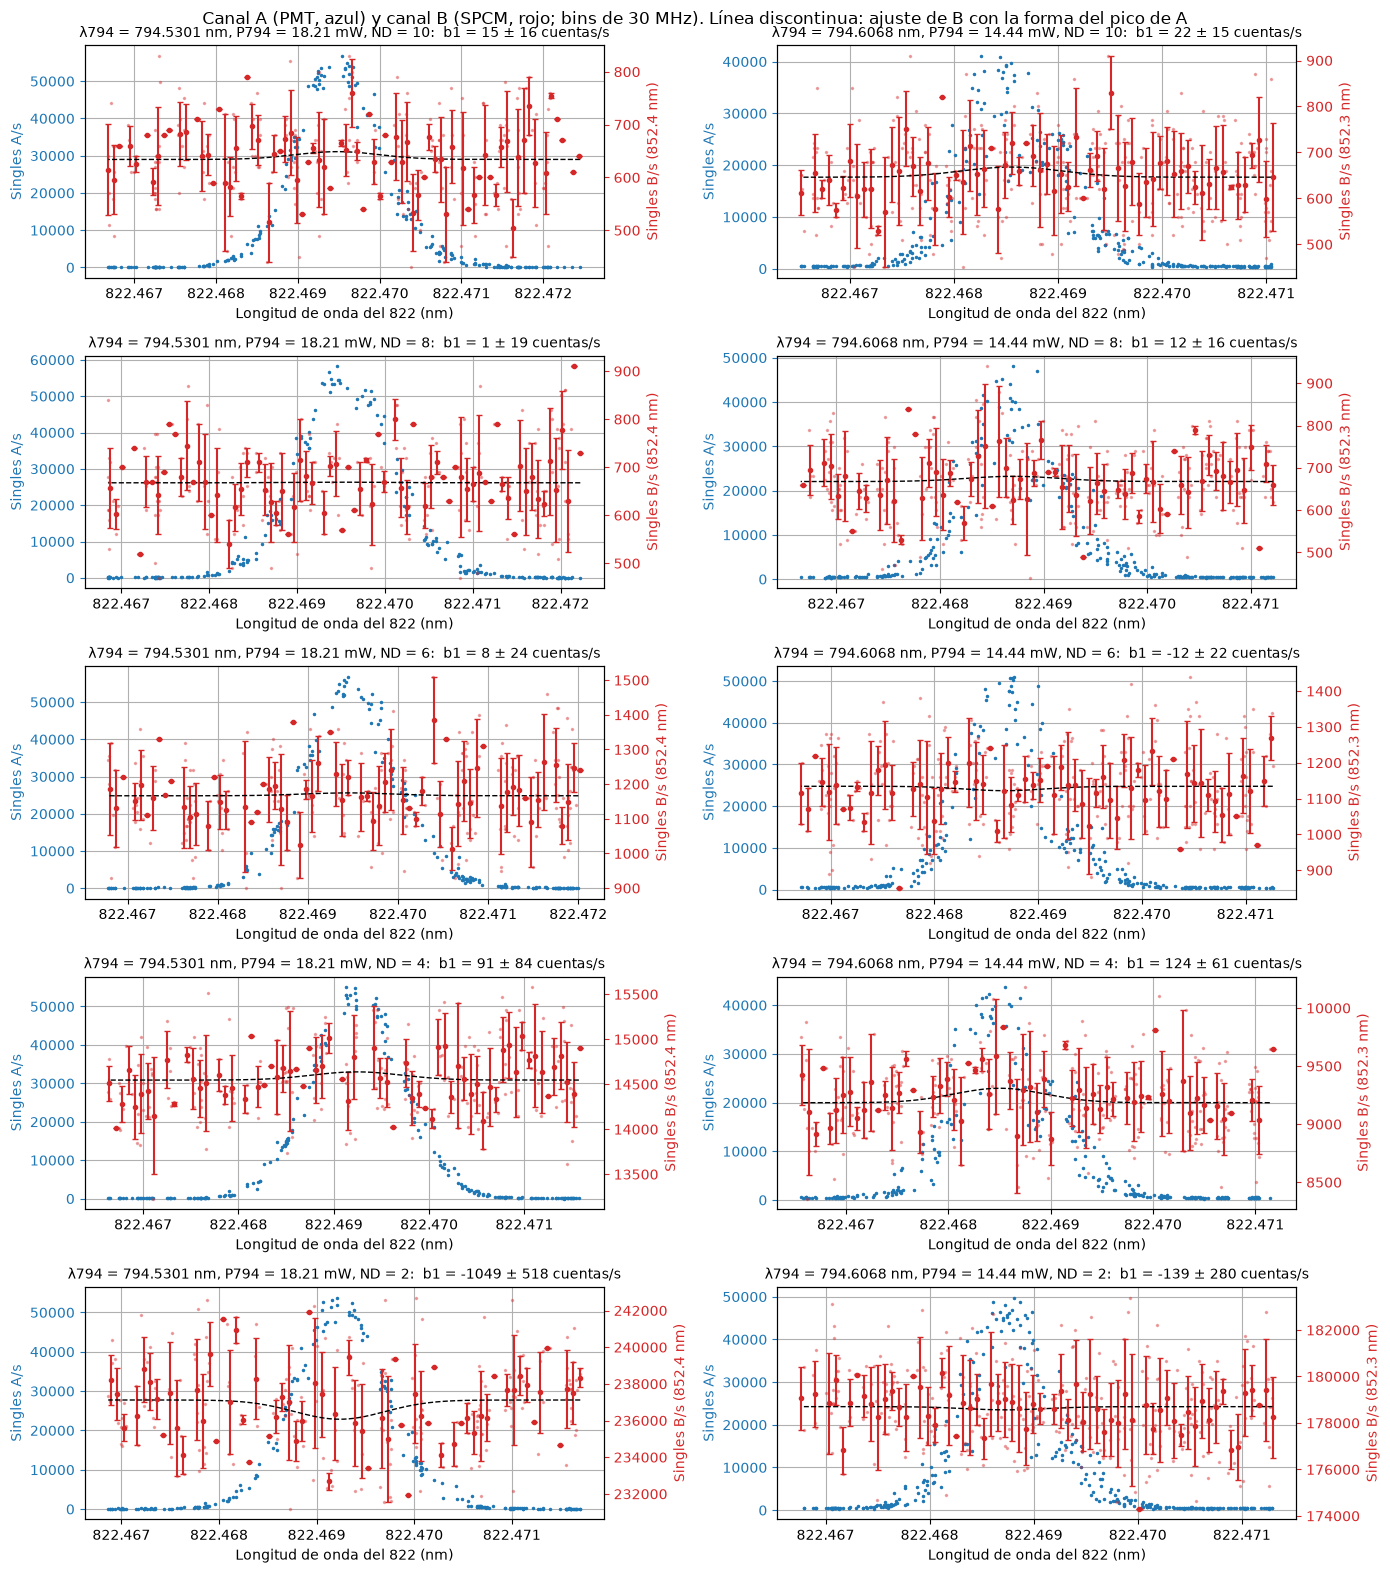

In [4]:
files = sorted(f for f in glob.glob(os.path.join(BASE, 'data', '*', '*.txt')) if 'readme' not in f)
ajustes = sorted({parse(os.path.basename(f)[:-4])['lam794'] for f in files})
nds = sorted({parse(os.path.basename(f)[:-4])['ND'] for f in files}, reverse=True)

fig, axs = plt.subplots(len(nds), len(ajustes), figsize=(7*len(ajustes), 3.2*len(nds)), squeeze=False)
resultados = []
for f in files:
    name = os.path.basename(f)[:-4]
    m = parse(name)
    D = load(f)
    nu = C_LIGHT/D['lam']
    ref = nu.mean()
    x = (nu - ref)*1e6  # MHz

    # 1. Pico de dos fotones en el canal A
    k = np.argmax(D['A'])
    pA, cA = curve_fit(gauss, x, D['A'], p0=[D['A'].min(), x[k], 100, D['A'].max()])
    g = np.exp(-(x - pA[1])**2/(2*pA[2]**2))

    # 2. Canal B con la forma del pico de A fija
    modelo = lambda X, b0, bt, b1: b0 + bt*(X[1] - 0.5) + b1*X[0]
    pB, cB = curve_fit(modelo, (g, D['t']), D['B'], p0=[D['B'].mean(), 0, 0])
    eB = np.sqrt(np.diag(cB))
    resid = D['B'] - modelo((g, D['t']), *pB)
    r, pval = pearsonr(D['A'], D['B'])

    u = np.sqrt(2*kB*(m['T'] + 273.15)/cte["m_Cs[kg]"])
    resultados.append(dict(m, name=name, n_bad=D['n_bad'],
                           lam0=C_LIGHT/(ref + pA[1]*1e-6), fwhm=2*np.sqrt(2*np.log(2))*abs(pA[2]),
                           fwhm_dop=2*np.sqrt(np.log(2))*u/(D['lam'].mean()*1e-9)/1e6,
                           b0=pB[0], b1=pB[2], e1=eB[2], z=pB[2]/eB[2],
                           lim=(max(pB[2], 0) + 2*eB[2])/pB[0], sB=resid.std(), sP=np.sqrt(pB[0]/T_EXP),
                           r=r, pval=pval))

    # Figura: canal A (azul, eje izquierdo) y canal B (rojo, eje derecho) frente a lambda_822
    ax = axs[nds.index(m['ND']), ajustes.index(m['lam794'])]
    ax.plot(D['lam'], D['A'], '.', ms=3, color='C0')
    ax.set_ylabel('Singles A/s', color='C0')
    ax.tick_params(axis='y', colors='C0')
    axb = ax.twinx()
    axb.plot(D['lam'], D['B'], '.', ms=3, color='C3', alpha=0.35)
    xb, mb, sb = binned(x, D['B'], 30.0)
    axb.errorbar(C_LIGHT/(ref + xb*1e-6), mb, yerr=sb, fmt='o', ms=3, capsize=2, color='C3')
    xx = np.linspace(x.min(), x.max(), 500)
    axb.plot(C_LIGHT/(ref + xx*1e-6), pB[0] + pB[2]*np.exp(-(xx - pA[1])**2/(2*pA[2]**2)), 'k--', lw=1)
    axb.set_ylabel(f'Singles B/s ({m["lam852"]} nm)', color='C3')
    axb.tick_params(axis='y', colors='C3')
    ax.ticklabel_format(axis='x', useOffset=False)
    ax.set_xlabel('Longitud de onda del 822 (nm)')
    ax.set_title(f'λ794 = {m["lam794"]} nm, P794 = {m["P794"]} mW, ND = {m["ND"]}:  '
                 f'b1 = {pB[2]:.0f} ± {eB[2]:.0f} cuentas/s', fontsize=10)
    ax.grid(True)
fig.suptitle('Canal A (PMT, azul) y canal B (SPCM, rojo; bins de 30 MHz). Línea discontinua: ajuste de B con la forma del pico de A',
             fontsize=12)
fig.tight_layout()
plt.show()

In [5]:
print(f"{'λ794':>9s} {'ND':>3s} {'desc.':>5s} {'λ0 822 (nm)':>12s} {'FWHM A':>7s} {'Doppler':>7s} "
      f"{'fondo b0':>9s} {'b1 ± σ (cuentas/s)':>20s} {'z':>5s} {'lím. 2σ':>8s} {'σ_B':>6s} {'Poisson':>7s} {'r(A,B)':>7s} {'p':>5s}")
for R in sorted(resultados, key=lambda R: (R['lam794'], -R['ND'])):
    print(f"{R['lam794']:9.4f} {R['ND']:3d} {R['n_bad']:5d} {R['lam0']:12.5f} {R['fwhm']:7.0f} {R['fwhm_dop']:7.0f} "
          f"{R['b0']:9.0f} {R['b1']:10.0f} ± {R['e1']:7.0f} {R['z']:5.1f} {100*R['lim']:7.2f}% "
          f"{R['sB']:6.0f} {R['sP']:7.0f} {R['r']:7.2f} {R['pval']:5.2f}")
print('\nFWHM en MHz de frecuencia del 822; "desc." = puntos descartados en la limpieza; '
      'lím. 2σ = (max(b1, 0) + 2σ)/b0; σ_B = dispersión de los residuos de B.')

     λ794  ND desc.  λ0 822 (nm)  FWHM A Doppler  fondo b0   b1 ± σ (cuentas/s)     z  lím. 2σ    σ_B Poisson  r(A,B)     p
 794.5301  10     2    822.46949     538     426       634         15 ±      16   0.9    7.49%     81      80    0.06  0.35
 794.5301   8     3    822.46955     547     426       668          1 ±      19   0.1    5.75%     86      82    0.01  0.85
 794.5301   6     2    822.46946     525     426      1166          8 ±      24   0.3    4.79%    116     108    0.02  0.81
 794.5301   4     2    822.46924     491     426     14547         91 ±      84   1.1    1.78%    402     381    0.08  0.24
 794.5301   2     1    822.46924     480     426    237121      -1049 ±     518  -2.0    0.44%   2525    1540   -0.13  0.05
 794.6068  10     3    822.46855     512     426       646         22 ±      15   1.4    8.13%     89      80    0.05  0.40
 794.6068   8     2    822.46871     471     426       668         12 ±      16   0.8    6.70%     85      82    0.07  0.25
 794.606

## Fondo del canal B frente al filtro ND

Si el fondo fuera ruido del detector, no cambiaría al quitar atenuación. Si es luz que viaja con los haces, debe crecer al bajar el ND. A la derecha, la amplitud $b_1$ relativa al fondo, que debería ser positiva y distinta de cero si hubiera señal de FWM.

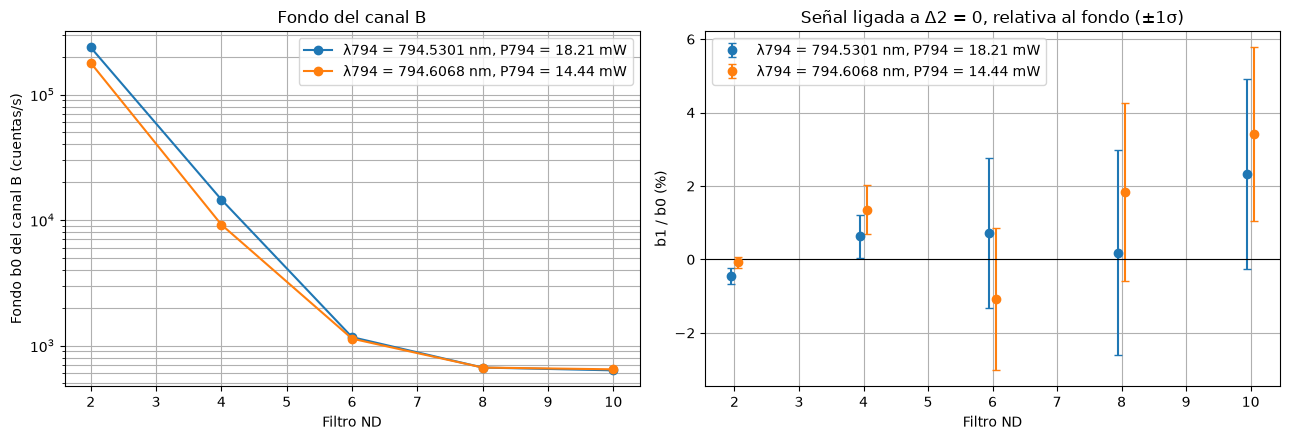

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
for j, l794 in enumerate(ajustes):
    Rs = sorted((R for R in resultados if R['lam794'] == l794), key=lambda R: R['ND'])
    lab = f"λ794 = {l794} nm, P794 = {Rs[0]['P794']} mW"
    nd = np.array([R['ND'] for R in Rs])
    a1.semilogy(nd, [R['b0'] for R in Rs], 'o-', label=lab)
    a2.errorbar(nd + 0.1*(j - 0.5), [100*R['b1']/R['b0'] for R in Rs], yerr=[100*R['e1']/R['b0'] for R in Rs],
                fmt='o', capsize=3, label=lab)
a1.set_xlabel('Filtro ND'); a1.set_ylabel('Fondo b0 del canal B (cuentas/s)')
a1.set_title('Fondo del canal B'); a1.grid(True, which='both'); a1.legend()
a2.axhline(0, color='k', lw=0.8)
a2.set_xlabel('Filtro ND'); a2.set_ylabel('b1 / b0 (%)')
a2.set_title('Señal ligada a Δ2 = 0, relativa al fondo (±1σ)'); a2.grid(True); a2.legend()
fig.tight_layout()
plt.show()

## Conclusiones

* **Canal A:** el pico de dos fotones aparece en los 10 barridos, centrado en 822.4685–822.4687 nm (λ794 = 794.6068 nm) y en 822.4692–822.4696 nm (λ794 = 794.5301 nm). La diferencia de ≈ 0.0008 nm (≈ 350 MHz) entre las dos series debería ser la misma resonancia; conviene revisar la deriva del medidor de longitud de onda. El FWHM ajustado (410–550 MHz) es comparable al ancho Doppler esperado a 80 °C (≈ 426 MHz). El exceso viene del desfase entre las rampas de subida y de bajada, que se ve como un pico doble.
* **Canal B:** la amplitud $b_1$ ligada a $\Delta_2 = 0$ es compatible con cero en todos los barridos ($|z| \le 2.0$). Los dos casos cerca de $2\sigma$ tienen signos opuestos, lo esperable por fluctuación en 10 pruebas. La correlación entre A y B es $|r| \le 0.13$. **No se detecta señal de 852 nm por encima del fondo.**
* **Ruido:** con ND ≥ 4 la dispersión de B coincide con el ruido de Poisson para $T_{exp} = 100$ ms. Con ND 2 es 1.2–1.6 veces mayor, de modo que la propia luz de fondo fluctúa.
* **Fondo:** con ND 8 y 10 el fondo es el mismo (≈ 650 cuentas/s), lo que corresponde al piso del detector. Con ND ≤ 6 crece con la transmisión: es luz que llega con los haces y pasa por el monocromador, y no depende de la resonancia atómica.
* **Límite:** con ND 2, cualquier señal con la forma del pico de dos fotones es menor que el 0.3–0.4 % del fondo (2σ). Para convertirlo en potencia a 852 nm falta calibrar la transmisión de los ND y la eficiencia de acople, monocromador y SPCM.

Siguientes pasos: identificar el origen del fondo (bloquear cada láser por separado y medir con ambos apagados) y calibrar el monocromador en 852 nm.